In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
!unzip gdrive/My\ Drive/bestartworkofalltime

Output streaming troncato alle ultime 5000 righe.
  inflating: resized/resized/Henri_Rousseau_61.jpg  
  inflating: resized/resized/Henri_Rousseau_62.jpg  
  inflating: resized/resized/Henri_Rousseau_63.jpg  
  inflating: resized/resized/Henri_Rousseau_64.jpg  
  inflating: resized/resized/Henri_Rousseau_65.jpg  
  inflating: resized/resized/Henri_Rousseau_66.jpg  
  inflating: resized/resized/Henri_Rousseau_67.jpg  
  inflating: resized/resized/Henri_Rousseau_68.jpg  
  inflating: resized/resized/Henri_Rousseau_69.jpg  
  inflating: resized/resized/Henri_Rousseau_7.jpg  
  inflating: resized/resized/Henri_Rousseau_70.jpg  
  inflating: resized/resized/Henri_Rousseau_8.jpg  
  inflating: resized/resized/Henri_Rousseau_9.jpg  
  inflating: resized/resized/Henri_de_Toulouse-Lautrec_1.jpg  
  inflating: resized/resized/Henri_de_Toulouse-Lautrec_10.jpg  
  inflating: resized/resized/Henri_de_Toulouse-Lautrec_11.jpg  
  inflating: resized/resized/Henri_de_Toulouse-Lautrec_12.jpg  
  inflati

In [ ]:
#download
from google.colab import files
files.download("model_deep_artist_identification.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Data Preparation

In [ ]:
import os
import random
import json
import cv2
import imageio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib


from PIL import Image
from tqdm import tqdm, tqdm_notebook

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import *
from tensorflow.keras.applications import *
from tensorflow.keras.callbacks import *
from tensorflow.keras.initializers import *
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import *
from keras.models import load_model
import keras.utils as image

In [ ]:
#SEED
from numpy.random import seed
seed(1)

import tensorflow
tf.random.set_seed(1)

In [ ]:
print(os.listdir("/content/"))

['.config', 'artists.csv', 'images', 'gdrive', 'resized', 'sample_data']


In [ ]:
artists = pd.read_csv('/content/artists.csv')
artists.shape

(50, 8)

In [ ]:
# Sort artists by number of paintings
artists = artists.sort_values(by=['paintings'], ascending=False)

# Create a dataframe with artists having more than 200 paintings
#artists_top = artists[artists['paintings'] >= 200].reset_index()
artists_top = artists[artists['paintings'] >= 250].reset_index()
artists_top = artists_top[['name', 'paintings']]
#artists_top['class_weight'] = max(artists_top.paintings)/artists_top.paintings
artists_top['class_weight'] = artists_top.paintings.sum() / (artists_top.shape[0] * artists_top.paintings)
artists_top

,name,paintings,class_weight
0,Vincent van Gogh,877,0.462942
1,Edgar Degas,702,0.578348
2,Pablo Picasso,439,0.924829
3,Pierre-Auguste Renoir,336,1.208333
4,Albrecht Dürer,328,1.237805
5,Paul Gauguin,311,1.305466
6,Francisco Goya,291,1.395189
7,Rembrandt,262,1.549618
8,Alfred Sisley,259,1.567568
9,Titian,255,1.592157


In [ ]:
# Set class weights - assign higher weights to underrepresented classes
class_weights = artists_top['class_weight'].to_dict()
class_weights

{0: 0.4629418472063854,
 1: 0.5783475783475783,
 2: 0.9248291571753986,
 3: 1.2083333333333333,
 4: 1.2378048780487805,
 5: 1.3054662379421222,
 6: 1.395189003436426,
 7: 1.549618320610687,
 8: 1.5675675675675675,
 9: 1.592156862745098}

In [ ]:
# There is some problem recognizing 'Albrecht_Dürer' (don't know why, worth exploring)
# So I'll update this string as directory name to df's
updated_name = "Albrecht_DuтХа├кrer".replace("_"," ")
#test
#updated_name = "Albrecht_DuтХа├кrer".replace("Albrecht_Dürer"," ")
#updated_name = "Albrecht_DuтХа├кrer".replace(" ","Albrecht_Dürer ")
#4rows 1 column
artists_top.iloc[4, 0] = updated_name



In [ ]:
# Explore images of top artists
images_dir = '/content/images/images'
artists_dirs = os.listdir(images_dir)
artists_top_name = artists_top['name'].str.replace(' ', '_').values

# See if all directories exist
for name in artists_top_name:
    if os.path.exists(os.path.join(images_dir, name)):
        print("Found -->", os.path.join(images_dir, name))
    else:
        print("Did not find -->", os.path.join(images_dir, name))

Found --> /content/images/images/Vincent_van_Gogh
Found --> /content/images/images/Edgar_Degas
Found --> /content/images/images/Pablo_Picasso
Found --> /content/images/images/Pierre-Auguste_Renoir
Found --> /content/images/images/Albrecht_DuтХа├кrer
Found --> /content/images/images/Paul_Gauguin
Found --> /content/images/images/Francisco_Goya
Found --> /content/images/images/Rembrandt
Found --> /content/images/images/Alfred_Sisley
Found --> /content/images/images/Titian


In [ ]:
path = '/content/images/images/Albrecht_DuтХа├кrer'  # in case the folder is in the same directory as the script
files = os.listdir(path)  # listdir gives you a list with all filenames in the provided path.
randomFile = random.choice(files)  # random.choice then selects a random file from your list
print(randomFile) #  prints the random filename

image = Image.open(path + '/' + randomFile)  # displayed the image
image.show()

Albrecht_DuтХа├кrer_142.jpg


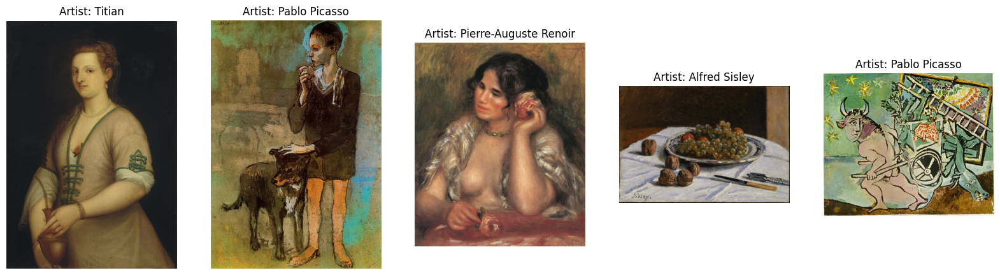

In [ ]:
# Print few random paintings
n = 5

#The subplot() function takes three arguments that describes the layout of the figure.
#The layout is organized in rows and columns, which are represented by the first and second argument.
#The third argument represents the index of the current plot.
fig, axes = plt.subplots(1, n, figsize=(20,10))

for i in range(n):
    random_artist = random.choice(artists_top_name)
    random_image = random.choice(os.listdir(os.path.join(images_dir, random_artist)))
    random_image_file = os.path.join(images_dir, random_artist, random_image)
    image = plt.imread(random_image_file)
    axes[i].imshow(image)
    axes[i].set_title("Artist: " + random_artist.replace('_', ' '))
    axes[i].axis('off')

plt.show()

In [ ]:
len(artists_top_name)

10

In [ ]:

for i in artists_top_name:
  print (i)

Vincent_van_Gogh
Edgar_Degas
Pablo_Picasso
Pierre-Auguste_Renoir
Albrecht_DuтХа├кrer
Paul_Gauguin
Francisco_Goya
Rembrandt
Alfred_Sisley
Titian


# Data Preprocessing

In [ ]:
# Augment data


#class_mode: Set this to None, to return only the images.
#shuffle: Set this to False, because you need to yield the images in “order”, to predict the outputs and match them with their unique ids or filenames.

batch_size = 16
train_input_shape = (224, 224, 3)
n_classes = artists_top.shape[0]


train_datagen = ImageDataGenerator(validation_split=0.2,
                                   rescale=1./255.,
                                   #rotation_range=45,
                                   #width_shift_range=0.5,
                                   #height_shift_range=0.5,
                                   shear_range=5,
                                   #zoom_range=0.7,
                                   horizontal_flip=True,
                                   vertical_flip=True,
                                  )

train_generator = train_datagen.flow_from_directory(directory=images_dir,
                                                    class_mode='categorical',
                                                    target_size=train_input_shape[0:2],
                                                    batch_size=batch_size,
                                                    subset="training",
                                                    shuffle=True,
                                                    classes=artists_top_name.tolist()

                                                   )

valid_generator = train_datagen.flow_from_directory(directory=images_dir,
                                                    class_mode='categorical',
                                                    target_size=train_input_shape[0:2],
                                                    batch_size=batch_size,
                                                    subset="validation",
                                                    shuffle=True,
                                                    classes=artists_top_name.tolist()

                                                   )

STEP_SIZE_TRAIN = train_generator.n//train_generator.batch_size
STEP_SIZE_VALID = valid_generator.n//valid_generator.batch_size
print("Total number of batches =", STEP_SIZE_TRAIN, "and", STEP_SIZE_VALID)

num_images = valid_generator.n
print("Number of images in the validation generator:", num_images)

Found 3252 images belonging to 10 classes.
Found 808 images belonging to 10 classes.
Total number of batches = 203 and 50
Number of images in the validation generator: 808


In [ ]:
artists_top_name

array(['Vincent_van_Gogh', 'Edgar_Degas', 'Pablo_Picasso',
       'Pierre-Auguste_Renoir', 'Albrecht_DuтХа├кrer', 'Paul_Gauguin',
       'Francisco_Goya', 'Rembrandt', 'Alfred_Sisley', 'Titian'],
      dtype=object)

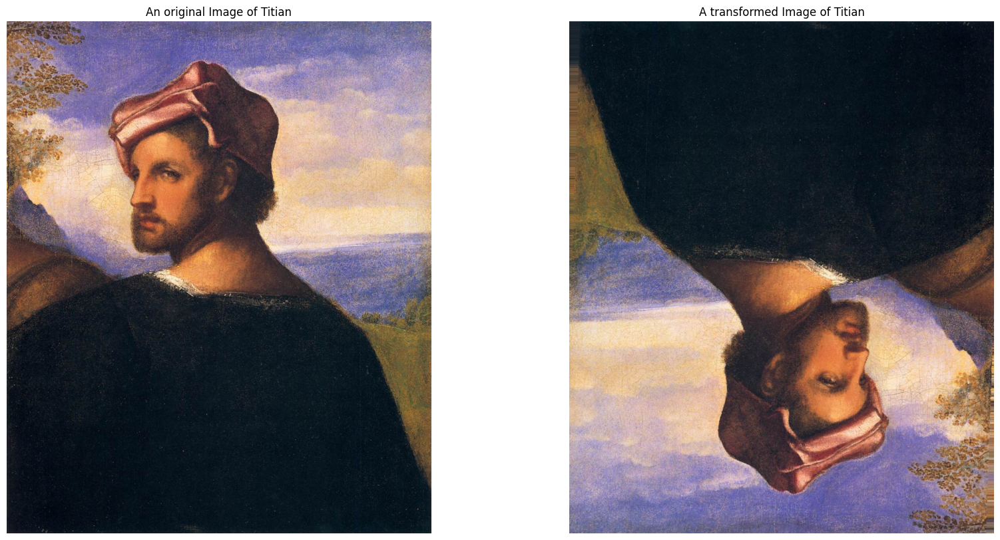

In [ ]:
# Print a random paintings and it's random augmented version
fig, axes = plt.subplots(1, 2, figsize=(20,10))

random_artist = random.choice(artists_top_name)
random_image = random.choice(os.listdir(os.path.join(images_dir, random_artist)))
random_image_file = os.path.join(images_dir, random_artist, random_image)

# Original image
image = plt.imread(random_image_file)
axes[0].imshow(image)
axes[0].set_title("An original Image of " + random_artist.replace('_', ' '))
axes[0].axis('off')

# Transformed image
aug_image = train_datagen.random_transform(image)
axes[1].imshow(aug_image)
axes[1].set_title("A transformed Image of " + random_artist.replace('_', ' '))
axes[1].axis('off')

plt.show()

# Create the Model

In [ ]:

#Specifying the include_top=False argument loads a network that doesn't include classification layers at the top, which is ideal for feature extraction.
#It's important to freeze the convolutional basis before compiling and training the model. Freezing (by setting layer.trainable = False)
#prevents the weights in a given layer from being updated during training.

# Load pre-trained model
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=train_input_shape)
#base_model =MobileNetV2(weights='imagenet', include_top=False, input_shape=train_input_shape)

for layer in base_model.layers:
    layer.trainable = True

94765736/94765736 [==============================] - 0s 0us/step


In [ ]:
# Add layers at the end

X = base_model.output

X = Flatten()(X)

X = Dense(16, kernel_initializer='he_uniform')(X)
#X = Dropout(0.5)(X)

X = BatchNormalization()(X)

X = Activation('relu')(X)

output = Dense(n_classes, activation='softmax')(X)

model = Model(inputs=base_model.input, outputs=output)

In [ ]:
#optimizer = Adam(lr=0.0001)
optimizer = Adam(learning_rate=0.0001)
model.compile(loss='categorical_crossentropy',
              optimizer=optimizer,
              metrics=['accuracy'])

In [ ]:
n_epoch = 10

early_stop = EarlyStopping(monitor='val_loss', patience=20, verbose=1,
                           mode='auto', restore_best_weights=True)


reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5,
                              verbose=1, mode='auto')

# Train the Model

In [ ]:

# Train the model - all layers
history1 = model.fit_generator(generator=train_generator, steps_per_epoch=STEP_SIZE_TRAIN,
#history1 = model.fit(train_generator, steps_per_epoch=STEP_SIZE_TRAIN,
                              validation_data=valid_generator, validation_steps=STEP_SIZE_VALID,
                              epochs=n_epoch,
                              shuffle=True,
                              verbose=1,
                              callbacks=[reduce_lr],
                              use_multiprocessing=True,
                              workers=16,
                              class_weight=class_weights
                             )

<ipython-input-21-701ca807fbcf>:11: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history1 = model.fit_generator(generator=train_generator, steps_per_epoch=STEP_SIZE_TRAIN,


Epoch 1/10
203/203 [==============================] - 152s 470ms/step - loss: 1.4772 - accuracy: 0.4691 - val_loss: 2.9949 - val_accuracy: 0.2175 - lr: 1.0000e-04
Epoch 2/10
203/203 [==============================] - 95s 450ms/step - loss: 1.0772 - accuracy: 0.6653 - val_loss: 3.3857 - val_accuracy: 0.0688 - lr: 1.0000e-04
Epoch 3/10
203/203 [==============================] - 97s 453ms/step - loss: 0.9078 - accuracy: 0.7590 - val_loss: 2.5851 - val_accuracy: 0.0850 - lr: 1.0000e-04
Epoch 4/10
203/203 [==============================] - 95s 450ms/step - loss: 0.7844 - accuracy: 0.8146 - val_loss: 2.7129 - val_accuracy: 0.2262 - lr: 1.0000e-04
Epoch 5/10
203/203 [==============================] - 95s 452ms/step - loss: 0.6816 - accuracy: 0.8504 - val_loss: 1.4930 - val_accuracy: 0.5425 - lr: 1.0000e-04
Epoch 6/10
203/203 [==============================] - 94s 443ms/step - loss: 0.6190 - accuracy: 0.8724 - val_loss: 0.9717 - val_accuracy: 0.7887 - lr: 1.0000e-04
Epoch 7/10
203/203 [=======

In [ ]:

# Freeze core ResNet layers and train again
for layer in model.layers:
    layer.trainable = False

#Unfreeze those layers you want to train (in this case, model.layers[:50])

#resnet50
for layer in model.layers[:50]:
#for layer in model.layers[:30]:
# MobileNet-v2 a convolutional neural network with 53 layers of depth.
#for layer in model.layers[:53]:
    layer.trainable = True

optimizer = Adam(lr=0.0001)

model.compile(loss='categorical_crossentropy',
              optimizer=optimizer,
              metrics=['accuracy'])

#n_epoch = 50
n_epoch=30
history2 = model.fit_generator(generator=train_generator, steps_per_epoch=STEP_SIZE_TRAIN,
                              validation_data=valid_generator, validation_steps=STEP_SIZE_VALID,
                              epochs=n_epoch,
                              shuffle=True,
                              verbose=1,
                              callbacks=[reduce_lr, early_stop],
                              use_multiprocessing=True,
                              workers=16,
                              class_weight=class_weights
                             )

<ipython-input-22-cbb2a11ee598>:29: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history2 = model.fit_generator(generator=train_generator, steps_per_epoch=STEP_SIZE_TRAIN,


Epoch 1/30
203/203 [==============================] - 106s 437ms/step - loss: 0.3696 - accuracy: 0.9184 - val_loss: 1.9914 - val_accuracy: 0.3537 - lr: 0.0010
Epoch 2/30
203/203 [==============================] - 95s 449ms/step - loss: 0.3056 - accuracy: 0.9354 - val_loss: 1.9212 - val_accuracy: 0.3988 - lr: 0.0010
Epoch 3/30
203/203 [==============================] - 109s 518ms/step - loss: 0.2859 - accuracy: 0.9407 - val_loss: 1.2585 - val_accuracy: 0.6175 - lr: 0.0010
Epoch 4/30
203/203 [==============================] - 94s 443ms/step - loss: 0.2386 - accuracy: 0.9515 - val_loss: 1.7534 - val_accuracy: 0.4400 - lr: 0.0010
Epoch 5/30
203/203 [==============================] - 91s 426ms/step - loss: 0.2064 - accuracy: 0.9552 - val_loss: 0.9844 - val_accuracy: 0.7200 - lr: 0.0010
Epoch 6/30
203/203 [==============================] - 93s 442ms/step - loss: 0.1869 - accuracy: 0.9570 - val_loss: 2.0175 - val_accuracy: 0.4437 - lr: 0.0010
Epoch 7/30
203/203 [==============================

In [ ]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 230, 230, 3)  0           ['input_1[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 112, 112, 64  9472        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                              

In [ ]:
# Merge history1 and history2

#A history objects has a history field is a dictionary which helds different training metrics spanned across every training epoch. So e.g. history.history['loss'][99]
#will return a loss of your model in a 100th epoch of training. In order to save that you could pickle this dictionary or simple save different lists from this dictionary to appropriate file.

history = {}
history['loss'] = history1.history['loss'] + history2.history['loss']
history['accuracy'] = history1.history['accuracy'] + history2.history['accuracy']
history['val_loss'] = history1.history['val_loss'] + history2.history['val_loss']
history['val_accuracy'] = history1.history['val_accuracy'] + history2.history['val_accuracy']
history['lr'] = history1.history['lr'] + history2.history['lr']

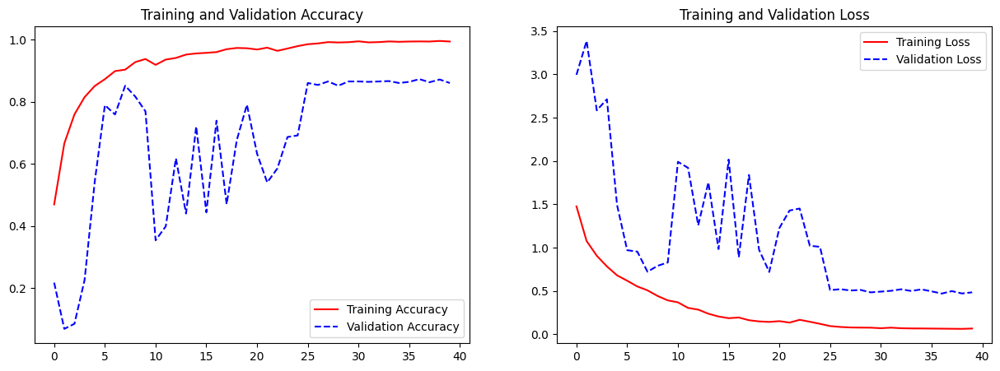

In [ ]:
# Plot the training graph
def plot_training(history):
    acc = history['accuracy']
    val_acc = history['val_accuracy']
    loss = history['loss']
    val_loss = history['val_loss']
    epochs = range(len(acc))

    fig, axes = plt.subplots(1, 2, figsize=(15,5))

    axes[0].plot(epochs, acc, 'r-', label='Training Accuracy')
    axes[0].plot(epochs, val_acc, 'b--', label='Validation Accuracy')
    axes[0].set_title('Training and Validation Accuracy')
    axes[0].legend(loc='best')

    axes[1].plot(epochs, loss, 'r-', label='Training Loss')
    axes[1].plot(epochs, val_loss, 'b--', label='Validation Loss')
    axes[1].set_title('Training and Validation Loss')
    axes[1].legend(loc='best')

    plt.show()

plot_training(history)

In [ ]:

# Prediction accuracy on train data
score = model.evaluate_generator(train_generator, verbose=1)
print("Prediction accuracy on train data =", score[1])

<ipython-input-26-1019fc591f3a>:13: UserWarning: `Model.evaluate_generator` is deprecated and will be removed in a future version. Please use `Model.evaluate`, which supports generators.
  score = model.evaluate_generator(train_generator, verbose=1)


204/204 [==============================] - 63s 308ms/step - loss: 0.0673 - accuracy: 0.9975
Prediction accuracy on train data = 0.9975399971008301


In [ ]:
# Prediction accuracy on CV data
score = model.evaluate_generator(valid_generator, verbose=1)
print("Prediction accuracy on CV data =", score[1])

<ipython-input-27-d4a6d1ee285c>:2: UserWarning: `Model.evaluate_generator` is deprecated and will be removed in a future version. Please use `Model.evaluate`, which supports generators.
  score = model.evaluate_generator(valid_generator, verbose=1)


51/51 [==============================] - 16s 313ms/step - loss: 0.4714 - accuracy: 0.8651
Prediction accuracy on CV data = 0.8650990128517151


# Evaluate the Model

1/1 [==============================] - 0s 29ms/step


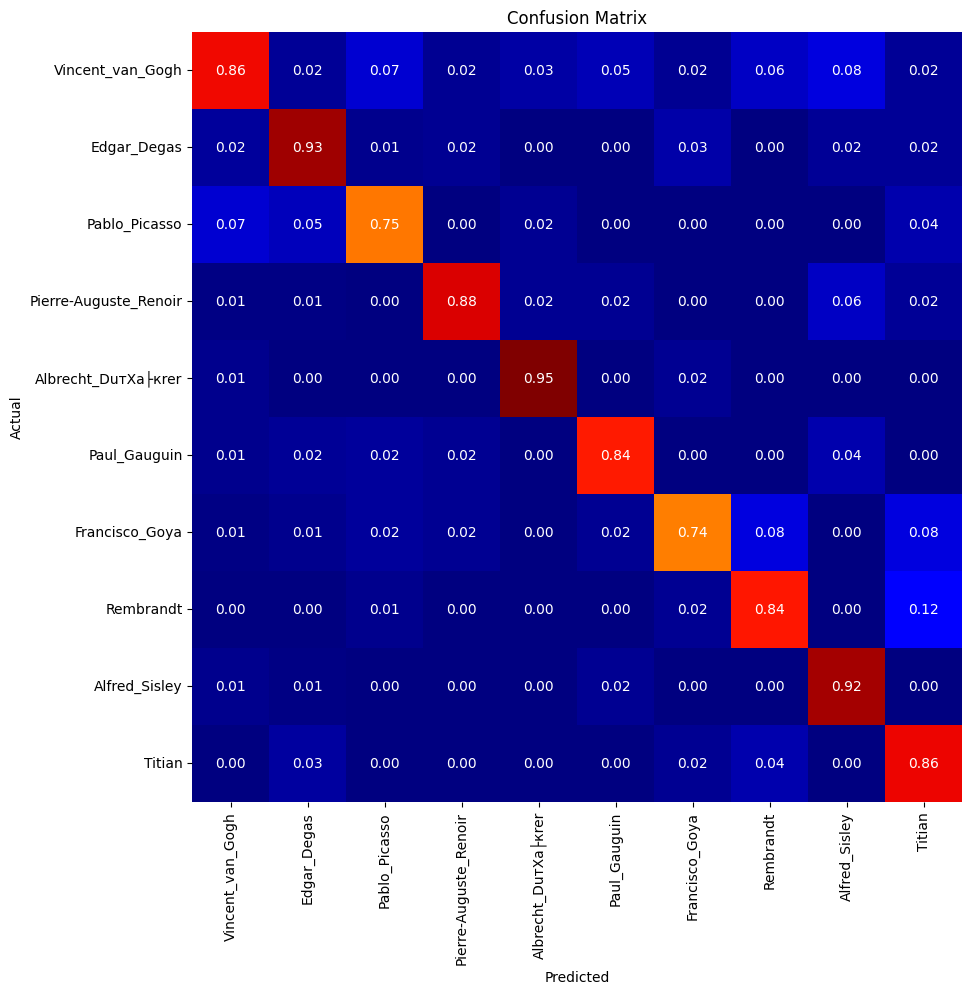

Classification Report:
                       precision    recall  f1-score   support

     Vincent_van_Gogh       0.86      0.86      0.86       172
          Edgar_Degas       0.86      0.93      0.89       138
        Pablo_Picasso       0.84      0.75      0.79        87
Pierre-Auguste_Renoir       0.93      0.88      0.90        65
  Albrecht_DuтХа├кrer       0.94      0.95      0.95        65
         Paul_Gauguin       0.90      0.84      0.87        62
       Francisco_Goya       0.88      0.74      0.80        58
            Rembrandt       0.83      0.84      0.83        51
        Alfred_Sisley       0.82      0.92      0.87        51
               Titian       0.75      0.86      0.80        51

             accuracy                           0.86       800
            macro avg       0.86      0.86      0.86       800
         weighted avg       0.86      0.86      0.86       800



In [ ]:

# Classification report and confusion matrix
from sklearn.metrics import *
import seaborn as sns

tick_labels = artists_top_name.tolist()

def showClassficationReport_Generator(model, valid_generator, STEP_SIZE_VALID):
    # Loop on each generator batch and predict
    y_pred, y_true = [], []
    for i in range(STEP_SIZE_VALID):
        (X,y) = next(valid_generator)
        y_pred.append(model.predict(X))
        y_true.append(y)

    # Create a flat list for y_true and y_pred
    y_pred = [subresult for result in y_pred for subresult in result]
    y_true = [subresult for result in y_true for subresult in result]

    # Update Truth vector based on argmax
    y_true = np.argmax(y_true, axis=1)
    y_true = np.asarray(y_true).ravel()

    # Update Prediction vector based on argmax
    y_pred = np.argmax(y_pred, axis=1)
    y_pred = np.asarray(y_pred).ravel()

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(10,10))
    conf_matrix = confusion_matrix(y_true, y_pred, labels=np.arange(n_classes))
    conf_matrix = conf_matrix/np.sum(conf_matrix, axis=1)
    sns.heatmap(conf_matrix, annot=True, fmt=".2f", square=True, cbar=False,
                cmap=plt.cm.jet, xticklabels=tick_labels, yticklabels=tick_labels,
                ax=ax)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
    ax.set_title('Confusion Matrix')
    plt.show()

    print('Classification Report:')
    print(classification_report(y_true, y_pred, labels=np.arange(n_classes), target_names=artists_top_name.tolist()))

showClassficationReport_Generator(model, valid_generator, STEP_SIZE_VALID)

# Test the Model

1/1 [==============================] - 0s 23ms/step


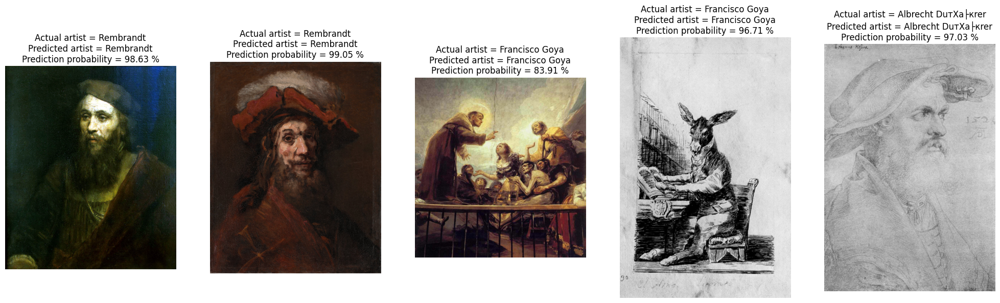

In [ ]:
# Prediction

n = 5
fig, axes = plt.subplots(1, n, figsize=(25,10))

for i in range(n):
    random_artist = random.choice(artists_top_name)
    random_image = random.choice(os.listdir(os.path.join(images_dir, random_artist)))
    random_image_file = os.path.join(images_dir, random_artist, random_image)

    # Original image

    test_image = tf.keras.utils.load_img(random_image_file, target_size=(train_input_shape[0:2]))

    # Predict artist
    #test_image = image.img_to_array(test_image)
    test_image = tf.keras.utils.img_to_array(test_image)
    test_image /= 255.
    test_image = np.expand_dims(test_image, axis=0)

    prediction = model.predict(test_image)
    prediction_probability = np.amax(prediction)
    prediction_idx = np.argmax(prediction)

    labels = train_generator.class_indices
    labels = dict((v,k) for k,v in labels.items())

    #print("Actual artist =", random_artist.replace('_', ' '))
    #print("Predicted artist =", labels[prediction_idx].replace('_', ' '))
    #print("Prediction probability =", prediction_probability*100, "%")

    title = "Actual artist = {}\nPredicted artist = {}\nPrediction probability = {:.2f} %" \
                .format(random_artist.replace('_', ' '), labels[prediction_idx].replace('_', ' '),
                        prediction_probability*100)

    # Print image
    axes[i].imshow(plt.imread(random_image_file))
    axes[i].set_title(title)
    axes[i].axis('off')

plt.show()

1/1 [==============================] - 0s 27ms/step


<ipython-input-30-3002f2e08be2>:9: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  web_image = imageio.imread(url)
<ipython-input-30-3002f2e08be2>:25: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  plt.imshow(imageio.imread(url))


Predicted artist = Edgar Degas
Prediction probability = 94.50280666351318 %


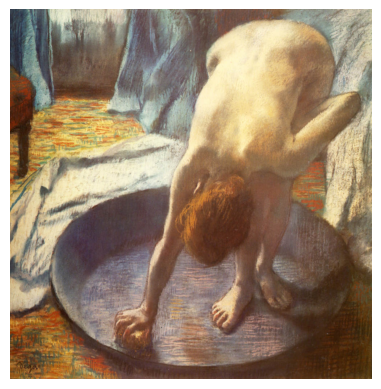

In [ ]:
# Predict from web - this is an image of Titian.
# Replace 'url' with any image of one of the 11 artists above and run this cell.

#url = 'https://www.gpsmycity.com/img/gd/2081.jpg'
url='/content/images/images/Edgar_Degas/Edgar_Degas_10.jpg'


web_image = imageio.imread(url)
web_image = cv2.resize(web_image, dsize=train_input_shape[0:2], )
#web_image = image.img_to_array(web_image)
web_image = tf.keras.utils.img_to_array(web_image)
web_image /= 255.
web_image = np.expand_dims(web_image, axis=0)


prediction = model.predict(web_image)
prediction_probability = np.amax(prediction)
prediction_idx = np.argmax(prediction)

print("Predicted artist =", labels[prediction_idx].replace('_', ' '))

print("Prediction probability =", prediction_probability*100, "%")

plt.imshow(imageio.imread(url))
plt.axis('off')
plt.show()

# Save the Model

In [ ]:
# save model
model.save('model_resnet50_deep_artist_identification.h5')
#To save and load the weights of the model, you would first use
model.save_weights('model_resnet50_deep_artist_identification_weights.h5')

In [ ]:
model.get_weights()

[array([[[[ 2.77831336e-03,  9.16331261e-03, -2.43197642e-02, ...,
            2.00662967e-02, -5.22691496e-02, -5.75413276e-03],
          [-3.96821722e-02,  1.06524415e-01, -5.93669340e-02, ...,
            1.71335302e-02,  1.55756539e-02,  1.32850232e-02],
          [-3.25525366e-02, -2.37061027e-02, -5.98723702e-02, ...,
           -1.20546585e-02,  2.95783505e-02,  6.81423396e-03]],
 
         [[ 1.25565901e-02, -1.89013015e-02, -9.20658838e-03, ...,
            9.01844539e-03, -3.51027702e-03,  1.58998705e-02],
          [-1.91312097e-03,  7.42689446e-02, -5.65211475e-02, ...,
            1.46309687e-02,  1.95028018e-02, -3.29710147e-03],
          [ 5.12775593e-03, -3.19956355e-02, -5.90957515e-02, ...,
           -2.07068305e-02, -2.86506973e-02, -4.17830609e-03]],
 
         [[ 2.99479030e-02, -2.53001582e-02,  2.01566722e-02, ...,
            2.00259183e-02,  1.82911810e-02, -4.54534218e-03],
          [ 3.21643651e-02,  7.15607628e-02, -4.36977819e-02, ...,
            2.392

# Optimize the model for the coversion in TFLite

In [ ]:
model.optimizer

In [ ]:
#to save the weights, as you've displayed. To load the weights, you would first need to build your model,
# and then call load_weights on the model, as in
model.load_weights('model_resnet50_deep_artist_identification_weights.h5')

In [ ]:
# Recreate the exact same model, including its weights and the optimizer
#new_model = tf.keras.models.load_model('model_deep_artist_identification.h5')
new_model = tf.keras.models.load_model('/content/model_resnet50_deep_artist_identification.h5')


# Show the model architecture
new_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 230, 230, 3)  0           ['input_1[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 112, 112, 64  9472        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                              

In [ ]:
#new model has the same weight as the previous one
new_model.get_weights()

[array([[[[ 2.77831336e-03,  9.16331261e-03, -2.43197642e-02, ...,
            2.00662967e-02, -5.22691496e-02, -5.75413276e-03],
          [-3.96821722e-02,  1.06524415e-01, -5.93669340e-02, ...,
            1.71335302e-02,  1.55756539e-02,  1.32850232e-02],
          [-3.25525366e-02, -2.37061027e-02, -5.98723702e-02, ...,
           -1.20546585e-02,  2.95783505e-02,  6.81423396e-03]],
 
         [[ 1.25565901e-02, -1.89013015e-02, -9.20658838e-03, ...,
            9.01844539e-03, -3.51027702e-03,  1.58998705e-02],
          [-1.91312097e-03,  7.42689446e-02, -5.65211475e-02, ...,
            1.46309687e-02,  1.95028018e-02, -3.29710147e-03],
          [ 5.12775593e-03, -3.19956355e-02, -5.90957515e-02, ...,
           -2.07068305e-02, -2.86506973e-02, -4.17830609e-03]],
 
         [[ 2.99479030e-02, -2.53001582e-02,  2.01566722e-02, ...,
            2.00259183e-02,  1.82911810e-02, -4.54534218e-03],
          [ 3.21643651e-02,  7.15607628e-02, -4.36977819e-02, ...,
            2.392

In [ ]:
new_model.optimizer

In [ ]:
#model evaluation test
predictions=new_model.evaluate(valid_generator)

51/51 [==============================] - 18s 323ms/step - loss: 0.4889 - accuracy: 0.8700


In [ ]:
loss, acc = new_model.evaluate(train_generator, verbose=2)
print('Restored model, accuracy: {:5.2f}%'.format(100 * acc))
print('Restored model, loss: {:5.2f}%'.format(100 * loss))

204/204 - 62s - loss: 0.0676 - accuracy: 0.9975 - 62s/epoch - 302ms/step
Restored model, accuracy: 99.75%
Restored model, loss:  6.76%


In [ ]:
loss, acc = new_model.evaluate(valid_generator, verbose=2)
print('Restored model, accuracy: {:5.2f}%'.format(100 * acc))
print('Restored model, loss: {:5.2f}%'.format(100 * loss))

51/51 - 15s - loss: 0.4876 - accuracy: 0.8651 - 15s/epoch - 290ms/step
Restored model, accuracy: 86.51%
Restored model, loss: 48.76%


In [ ]:
# Prediction accuracy on CV data
score = new_model.evaluate_generator(valid_generator, verbose=1)
print("Prediction accuracy on CV data =", score[1])

<ipython-input-40-8821ab500e22>:2: UserWarning: `Model.evaluate_generator` is deprecated and will be removed in a future version. Please use `Model.evaluate`, which supports generators.
  score = new_model.evaluate_generator(valid_generator, verbose=1)


51/51 [==============================] - 15s 302ms/step - loss: 0.4818 - accuracy: 0.8700
Prediction accuracy on CV data = 0.8700494766235352


# Test prediction after optimization

1/1 [==============================] - 0s 36ms/step


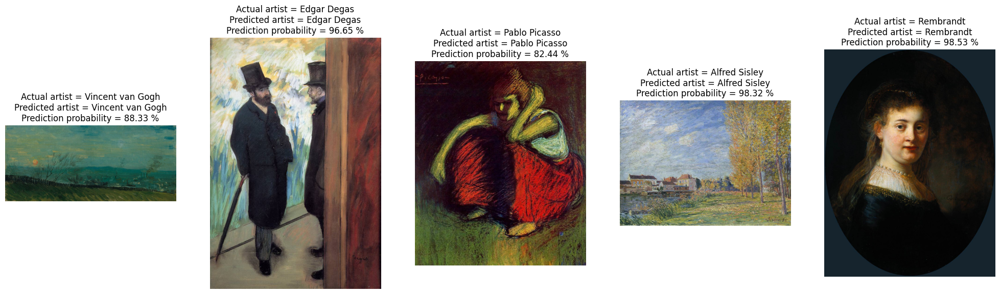

In [ ]:
#PREDICT Prediction

n = 5
fig, axes = plt.subplots(1, n, figsize=(25,10))

for i in range(n):
    random_artist = random.choice(artists_top_name)
    random_image = random.choice(os.listdir(os.path.join(images_dir, random_artist)))
    random_image_file = os.path.join(images_dir, random_artist, random_image)

    # Original image

    test_image = tf.keras.utils.load_img(random_image_file, target_size=(train_input_shape[0:2]))

    # Predict artist
    #test_image = image.img_to_array(test_image)
    test_image = tf.keras.utils.img_to_array(test_image)
    test_image /= 255.
    test_image = np.expand_dims(test_image, axis=0)

    prediction = new_model.predict(test_image)
    prediction_probability = np.amax(prediction)
    prediction_idx = np.argmax(prediction)

    labels = train_generator.class_indices
    labels = dict((v,k) for k,v in labels.items())

    #print("Actual artist =", random_artist.replace('_', ' '))
    #print("Predicted artist =", labels[prediction_idx].replace('_', ' '))
    #print("Prediction probability =", prediction_probability*100, "%")

    title = "Actual artist = {}\nPredicted artist = {}\nPrediction probability = {:.2f} %" \
                .format(random_artist.replace('_', ' '), labels[prediction_idx].replace('_', ' '),
                        prediction_probability*100)


    # Print image
    axes[i].imshow(plt.imread(random_image_file))
    axes[i].set_title(title)
    axes[i].axis('off')

plt.show()

<ipython-input-42-c5cdf500fcb1>:16: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  web_image = imageio.imread(url)


1/1 [==============================] - 0s 24ms/step
Predicted artist = Titian
Prediction probability = 92.78024435043335 %


<ipython-input-42-c5cdf500fcb1>:37: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  plt.imshow(imageio.imread(url))


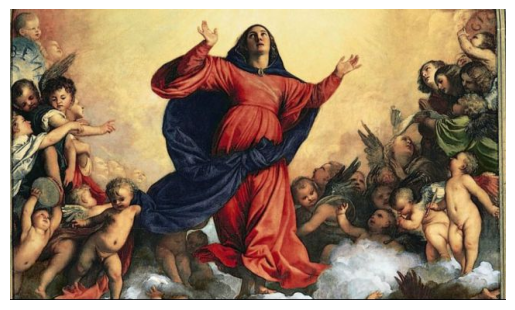

In [ ]:
# PREDICT IMAGE

# Predict from web - this is an image of Titian.
# Replace 'url' with any image of one of the 11 artists above and run this cell.

url = 'https://www.gpsmycity.com/img/gd/2081.jpg'
#url = '/content/images/images/Edvard_Munch/Edvard_Munch_10.jpg'
#url='https://b2cfurniture.com.au/pub/media/catalog/product/cache/3fb871f48f7af5e44260f2d9fd3932a9/e/l/elm-modern-hardwood-dining-chair-black-hardwood-frame-eco-friendly-beige-fabric_3_.jpg'


web_image = imageio.imread(url)
web_image = cv2.resize(web_image, dsize=(train_input_shape[0:2]), )
web_image = image.img_to_array(web_image)
web_image /= 255.
web_image = np.expand_dims(web_image, axis=0)


prediction = new_model.predict(web_image)
prediction_probability = np.amax(prediction)
prediction_idx = np.argmax(prediction)


if prediction_probability > 0.60 :

  print("Predicted artist =", labels[prediction_idx].replace('_', ' '))
  print("Prediction probability =", prediction_probability*100, "%")


else :
  print("No artist recognized with sufficient confidence")

plt.imshow(imageio.imread(url))
plt.axis('off')
plt.show()

# Save the optimized Model

In [ ]:

model.save('model_deep_artist_identification.h5')

In [ ]:
model.save_weights('deep_artist_identification_weights.h5')

In [ ]:

new_model = load_model('model_deep_artist_identification.h5')

In [ ]:
from google.colab import files
files.download('model_deep_artist_identification.h5')

In [ ]:
from google.colab import files
files.download('deep_artist_identification_weights.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conversion of the TF  model  in the TFlite version

In [ ]:
#model = tf.keras.models.load_model('/content/gdrive/MyDrive/model_deep_artist_identificationv3.h5')
model = tf.keras.models.load_model('/content/gdrive/MyDrive/model_resnet50_deep_artist_identification.h5')
converter = tf.lite.TFLiteConverter.from_keras_model(model = model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

new_input_shape = (16, 224, 224, 3)

#converter.representative_dataset = tf.lite.RepresentativeDataset(train_generator)

#converter.optimizations = [tf.lite.Optimize.OPTIMIZE_FOR_SIZE]
converter.target_spec.supported_ops = [
  tf.lite.OpsSet.TFLITE_BUILTINS, # enable TensorFlow Lite ops.
  tf.lite.OpsSet.SELECT_TF_OPS # enable TensorFlow ops.
]
tflite_model = converter.convert()
open("convtfl_model_resnet50_deep_artist_identification.tflite", "wb").write(tflite_model)

25531656

In [ ]:
# Load TFLite model and allocate tensors.
interpreter = tf.lite.Interpreter(model_path='/content/gdrive/MyDrive/convtfl_model_resnet50_deep_artist_identification.tflite')
interpreter.allocate_tensors()

# Get input and output tensors.
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [ ]:
interpreter.resize_tensor_input(input_details[0]['index'], (16, 224, 224, 3))
interpreter.resize_tensor_input(output_details[0]['index'], (16, 10))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("== Input details ==")
print("name:", input_details[0]['name'])
print("shape:", input_details[0]['shape'])
print("type:", input_details[0]['dtype'])

print("\n== Output details ==")
print("name:", output_details[0]['name'])
print("shape:", output_details[0]['shape'])
print("type:", output_details[0]['dtype'])

== Input details ==
name: serving_default_input_1:0
shape: [ 16 224 224   3]
type: <class 'numpy.float32'>

== Output details ==
name: StatefulPartitionedCall:0
shape: [16 10]
type: <class 'numpy.float32'>


In [ ]:
val_image_batch, _ = next(valid_generator)
val_image_batch = val_image_batch[:16].astype(np.float32)

interpreter.set_tensor(input_details[0]['index'], val_image_batch)

interpreter.invoke()

tflite_model_predictions = interpreter.get_tensor(output_details[0]['index'])
print("Prediction results shape:", tflite_model_predictions.shape)

Prediction results shape: (16, 10)


In [ ]:
# Convert prediction results to Pandas dataframe, for better visualization

tflite_pred_dataframe = pd.DataFrame(tflite_model_predictions)
tflite_pred_dataframe.columns = artists_top_name

print("TFLite prediction results for the first elements")
tflite_pred_dataframe.head()

TFLite prediction results for the first elements


,Vincent_van_Gogh,Edgar_Degas,Pablo_Picasso,Pierre-Auguste_Renoir,Albrecht_DuтХа├кrer,Paul_Gauguin,Francisco_Goya,Rembrandt,Alfred_Sisley,Titian
0,0.952420,0.005626,0.004335,0.003571,0.007507,0.019566,0.000342,0.000082,0.000438,0.006113
1,0.022026,0.002008,0.959839,0.001557,0.003023,0.002157,0.000258,0.003931,0.000748,0.004453
2,0.000355,0.961706,0.011995,0.000476,0.000372,0.000753,0.001534,0.002721,0.000885,0.019202
3,0.000370,0.003631,0.000111,0.003533,0.000050,0.000099,0.967338,0.001549,0.000307,0.023013
4,0.012103,0.001178,0.002903,0.921822,0.008471,0.034243,0.000930,0.007472,0.007019,0.003858


In [ ]:
# Test the TensorFlow Lite model on random input data.
input_shape = input_details[0]['shape']
inputs, outputs = [], []
for _ in range(224):
  input_data = np.array(np.random.random_sample(input_shape), dtype=np.float32)
  interpreter.set_tensor(input_details[0]['index'], input_data)

  interpreter.invoke()
  tflite_results = interpreter.get_tensor(output_details[0]['index'])

  # Test the TensorFlow model on random input data.
  tf_results = model(tf.constant(input_data))
  output_data = np.array(tf_results)

  inputs.append(input_data[0][0])
  outputs.append(output_data[0][0])

Image Shape ( 224 , 224 )
[5.9214176e-04 3.3005963e-03 1.7240511e-04 3.3892968e-03 1.2426871e-03
 1.3982198e-02 3.5765269e-04 3.9630509e-03 9.7029412e-01 2.7057261e-03]
This image most likely belongs to Alfred_Sisley with a 22.61 percent confidence.


<ipython-input-46-3a384eb78bac>:44: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  plt.imshow(imageio.imread(image_url))


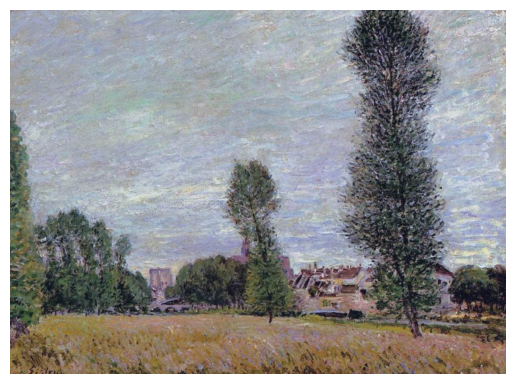

In [ ]:
def lite_model(images):
  interpreter.allocate_tensors()
  interpreter.set_tensor(interpreter.get_input_details()[0]['index'], images)
  interpreter.invoke()
  return interpreter.get_tensor(interpreter.get_output_details()[0]['index'])

class_names = ["Vincent_van_Gogh",
"Edgar_Degas",
"Pablo_Picasso",
"Pierre-Auguste_Renoir",
"Albrecht_DuтХа├кrer",
"Paul_Gauguin",
"Francisco_Goya",
"Rembrandt",
"Alfred_Sisley",
"Titian" ]


interpreter = tf.lite.Interpreter( model_path='/content/gdrive/MyDrive/convtfl_model_resnet50_deep_artist_identification.tflite' )
interpreter.allocate_tensors()
_, height, width, _ = interpreter.get_input_details()[0]['shape']
print("Image Shape (", width, ",", height, ")")

image_url = '/content/images/images/Alfred_Sisley/Alfred_Sisley_239.jpg'
img = tf.keras.preprocessing.image.load_img(image_url, target_size=( width, height ) )
#os.remove(image_url) # Remove the cached file

img_array = tf.keras.preprocessing.image.img_to_array(img)
probs_lite = lite_model( np.expand_dims(img_array, axis=0)/255 )[0]
print ( probs_lite )

label_index= np.argmax(probs_lite)
#score = tf.nn.softmax(probs_lite)

print(
  "This image most likely belongs to {} with a {:.2f} percent confidence."
  #.format(class_names[label_index], 100 * np.max(score))
  .format(class_names[label_index], 100 * np.max(probs_lite))
)
plt.imshow(imageio.imread(image_url))
plt.axis('off')
plt.show()